In [41]:
import numpy as np
import matplotlib.pyplot as plt

1. Particle setup and charge deposit

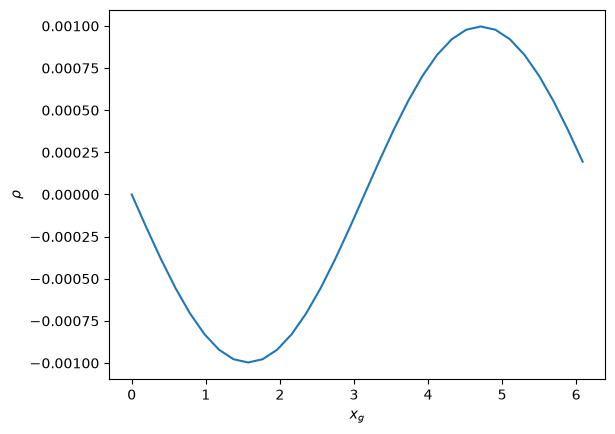

In [42]:
L = 2 * np.pi       #length of the domain
NG = 32             #number of grid points
dx = L / NG         #spacing between grid points
N = 128             #number of electrons (particles)
wp = 1              #plasma frequency, taken 1 for simplicity
eps0 = 1            #constant, define as 1
QM = -1             #charge to mass ratio of an electron
dt = 0.05

n0 = N / L                  #number density
q = wp**2*eps0 / (n0*QM)    #charge of one electron
m = q / QM                  #mass of one electron

#placing the electrons

x0 = (np.arange(N) + 0.5) / n0      #each electron centred in its location
v0 = np.zeros(N)                    #all velocities start at zero
xp = x0 + 0.001 * np.cos(x0)        #perturbation to start oscillations

#converting particle positions into grid charge

rho = np.zeros(NG)

for i in range(N):
    s = xp[i] / dx              #grid coordinate
    j = int(np.floor(s))        #left grid index
    f = s - j                   #fractional distance from the left grid point
    rho[j] += q*(1 - f)/dx      #left point gets (1 - f) charge share
    rho[(j+1) % NG] += q*f/dx   #right point gets f charge share. modulo ensures periodicity

rho -= rho.mean()       #since fixed ions cancel the average charge

xg = np.arange(NG) * dx
plt.plot(xg, rho)
plt.xlabel('$x_g$')
plt.ylabel('$\\rho$')
plt.show()

2. Solving Poisson's equation

In [43]:
k = 2*np.pi * np.fft.fftfreq(NG, d=dx)      #Fourier wavenumber array
rho_hat = np.fft.fft(rho)

phi_hat = np.zeros(NG, dtype=complex)
phi_hat[1:] = rho_hat[1:] / (eps0 * k[1:]**2)
E_hat = -1j * k * phi_hat

phi = np.real(np.fft.ifft(phi_hat))         #grid potential
E = np.real(np.fft.ifft(E_hat))             #grid EF

3. Initialising leapfrog velocity staggering

In [44]:
#interpolating the electric field at grid points

Ep = np.zeros(N)
ap = np.zeros(N)
vp = np.zeros(N)

for i in range(N):
    s = xp[i] / dx                             #grid coordinate
    j = int(np.floor(s))                       #left grid index
    f = s - j                                  #fractional distance from the left grid point
    Ep[i] = (1 - f)*E[j] + f*E[(j+1) % NG]     #interpolation
    ap[i] = QM * Ep[i]                         #particle acceleration
    vp[i] = v0[i] - QM * Ep[i] * (dt/2)        #initial velocity staggering

4. One leapfrog update (single-step demonstration)

In [45]:
for i in range(N):
    s = xp[i] / dx
    j = int(np.floor(s))
    f = s - j

    Ep[i] = (1-f)*E[j] + f*E[(j+1)%NG]
    ap[i] = QM * Ep[i]
    vp[i] += ap[i] * dt
    xp[i] += vp[i] * dt
    xp[i] = xp[i] % L                      #periodic BC

5. Diagnostics - KE, ES field energy, TE

In [46]:
WK = 0.5 * m * np.sum(vp**2)                #KE
WE = (eps0/2) * dx * np.sum(E**2)           #field energy
WT = WK + WE

## Analytical reference

The numerical simulation can be compared with the small-amplitude, one-dimensional
cold-plasma result.

Let the displacement of an electron from its equilibrium position be
$$
x(x_0,t)=x_0+\xi(x_0,t),
$$
where $x_0$ is its initial equilibrium position and $|\xi|\ll L$.

For a small displacement, the electron-density perturbation is given by the
linearised continuity equation:
$$
\delta n=-n_0\frac{\partial \xi}{\partial x_0}.
$$
The ions remain fixed, so the perturbed charge density is
$$
\rho=q\,\delta n
=-n_0q\frac{\partial \xi}{\partial x_0}.
$$

Using Gauss's law,
$$
\frac{\partial E}{\partial x_0}
=\frac{\rho}{\varepsilon_0}
=-\frac{n_0q}{\varepsilon_0}
\frac{\partial \xi}{\partial x_0}.
$$
For a non-zero spatial mode (with zero mean electric field), this gives
$$
E=-\frac{n_0q}{\varepsilon_0}\xi.
$$

The electron equation of motion is
$$
m\frac{\partial^2\xi}{\partial t^2}=qE.
$$
Substituting the electric field,
$$
\frac{\partial^2\xi}{\partial t^2}
+\frac{n_0q^2}{\varepsilon_0m}\xi=0.
$$

Defining the electron plasma frequency,
$$
\boxed{\omega_p=\sqrt{\frac{n_0q^2}{\varepsilon_0m}}},
$$
the displacement therefore satisfies
$$
\boxed{\frac{\partial^2\xi}{\partial t^2}+\omega_p^2\xi=0.}
$$

In this notebook, the initial displacement is
$$
\xi(x_0,0)=0.001\cos(x_0),
\qquad
\left.\frac{\partial\xi}{\partial t}\right|_{t=0}=0.
$$
Thus the analytical linear-theory prediction is
$$
\boxed{
x_i(t)-x_{i,0}
=0.001\cos(x_{i,0})\cos(\omega_pt).
}
$$

Since the chosen parameters give $\omega_p=1$, the predicted period is
$$
T_p=\frac{2\pi}{\omega_p}=2\pi\approx6.283.
$$

This is the continuum, small-amplitude cold-plasma result.

7. Time Evolution

In [47]:
NT = 500                         #number of time steps
time = (np.arange(NT) + 1)*dt

#resetting the initial particle conditions
xp = x0 + 0.001*np.cos(x0)
vp = np.zeros(N)

for i in range(N):
    vp[i] = v0[i] - QM*Ep[i]*(dt/2)

WK = np.zeros(NT)                #kinetic energy history
WE = np.zeros(NT)                #electric field energy history
WT = np.zeros(NT)                #total energy history

xp_history = np.zeros((NT, N))  #history of all particle positions

for n in range(NT):

    #depositing particle charge onto the grid

    rho = np.zeros(NG)

    for i in range(N):
        s = xp[i] / dx
        j = int(np.floor(s))
        f = s - j

        rho[j] += q*(1-f)/dx
        rho[(j+1)%NG] += q*f/dx

    rho -= rho.mean()

    #solving Poisson's equation

    rho_hat = np.fft.fft(rho)

    phi_hat = np.zeros(NG, dtype=complex)
    phi_hat[1:] = rho_hat[1:] / (eps0*k[1:]**2)

    E_hat = -1j*k*phi_hat

    phi = np.real(np.fft.ifft(phi_hat))
    E = np.real(np.fft.ifft(E_hat))

    #interpolating EF and advancing particle velocities and positions

    for i in range(N):
        s = xp[i] / dx
        j = int(np.floor(s))
        f = s - j

        Ep[i] = (1-f)*E[j] + f*E[(j+1)%NG]
        ap[i] = QM*Ep[i]

        vp[i] += ap[i]*dt
        xp[i] += vp[i]*dt
        xp[i] = xp[i] % L

    #calculating energies

    WK[n] = 0.5*m*np.sum(vp**2)
    WE[n] = (eps0/2)*dx*np.sum(E**2)
    WT[n] = WK[n] + WE[n]

    #storing particle positions

    xp_history[n,:] = xp


### Comparing with the analytical oscillation

The analytical solution predicts that every particle's displacement has the same
temporal factor, $\cos(\omega_p t)$, while its spatial amplitude is proportional
to its initial perturbation, $\cos(x_{i,0})$.

The code below extracts the amplitude of this spatial mode from all simulated
particles:
$$
A_{\mathrm{num}}(t)=\frac{2}{N}\sum_{i=1}^{N}
[x_i(t)-x_{i,0}]\cos(x_{i,0}).
$$
For the initial positions used here, this projection returns the coefficient of
the $\cos(x_0)$ mode.

It is compared with
$$
A_{\mathrm{analytical}}(t)=0.001\cos(\omega_pt).
$$


8. Validation against the analytical oscillation

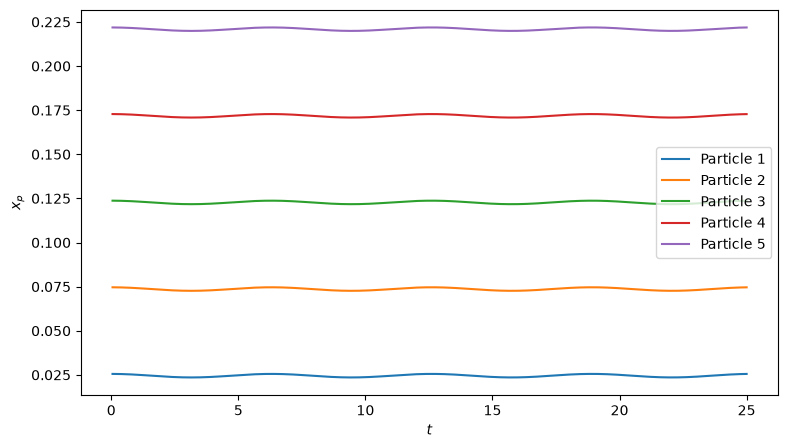

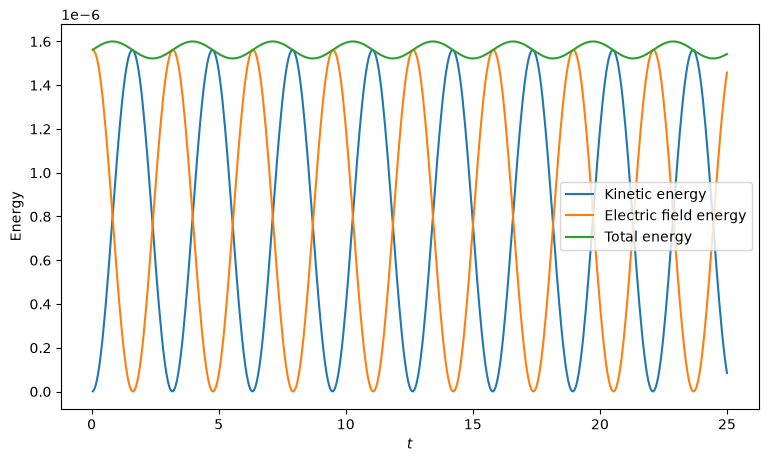

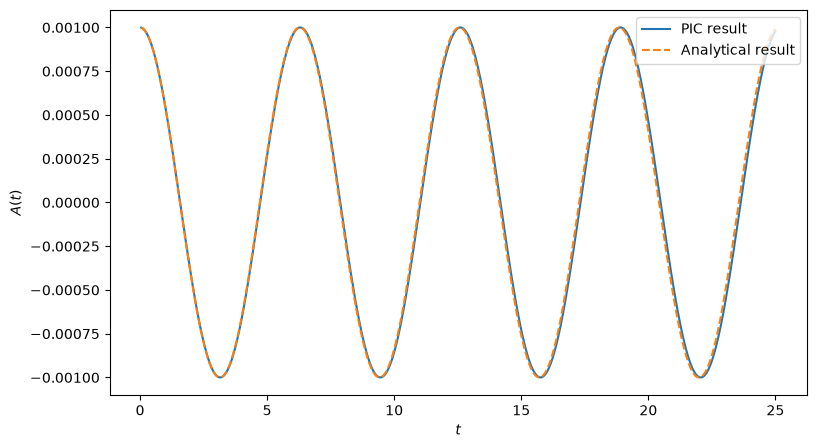

Theoretical plasma frequency = 1
Theoretical plasma period = 6.283185307179586
RMS amplitude difference = 3.200731702779235e-05
Relative RMS difference (%) = 4.538511519289857


In [48]:
plt.figure(figsize=(9,5))

for i in range(5):
    plt.plot(time, xp_history[:,i], label=f'Particle {i+1}')

plt.xlabel('$t$')
plt.ylabel('$x_p$')
plt.legend()
plt.show()

plt.figure(figsize=(9,5))

plt.plot(time, WK, label='Kinetic energy')
plt.plot(time, WE, label='Electric field energy')
plt.plot(time, WT, label='Total energy')

plt.xlabel('$t$')
plt.ylabel('Energy')
plt.legend()
plt.show()

#comparing the numerical oscillation with the analytical result

xi_num = xp_history - x0
xi_analytical = 0.001*np.cos(x0)[None,:]*np.cos(wp*time[:,None])

#projecting the displacement onto the initial spatial mode cos(x0)
amplitude_num = (2/N)*np.sum(xi_num*np.cos(x0)[None,:], axis=1)
amplitude_analytical = 0.001*np.cos(wp*time)

plt.figure(figsize=(9,5))

plt.plot(time, amplitude_num, label='PIC result')
plt.plot(time, amplitude_analytical, '--', label='Analytical result')

plt.xlabel('$t$')
plt.ylabel('$A(t)$')
plt.legend()
plt.show()

#calculating the relative RMS difference between the numerical and analytical amplitudes
rms_error = np.sqrt(np.mean((amplitude_num-amplitude_analytical)**2))
relative_error = rms_error/np.sqrt(np.mean(amplitude_analytical**2))

print('Theoretical plasma frequency =', wp)
print('Theoretical plasma period =', 2*np.pi/wp)
print('RMS amplitude difference =', rms_error)
print('Relative RMS difference (%) =', 100*relative_error)
